# Read a saved Chebyshev IP: one order

Load **`ip_model.json`**, evaluate one order on a wavelength grid, and plot the physical two-Gaussian parameters and intrinsic cumulants κ₁–κ₅. This notebook uses only the JSON, NumPy and Matplotlib; it does not import the fitting package or read the original spectra.

Change `model_path`, `order`, and `n_wavelengths` below. The curves represent the stored coefficient estimate (MAP or posterior-median coefficients). The compact JSON contains no posterior draws, so these plots show point estimates without credible intervals.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
project_dir = Path.cwd().parent if Path.cwd().name == 'examples' else Path.cwd()
model_path = project_dir / (
    'examples/results/thar_ip_analysis_chebyshev_for_jaxstar/'
    'orders_104_105_106/one_call/20261104_001503_693679/ip_model.json'
)
order = 104
n_wavelengths = 1000


In [3]:
with model_path.open() as handle:
    model = json.load(handle)

if model['schema_version'] != 1:
    raise ValueError('This notebook supports ip_model.json schema 1.')
if model['basis']['name'] != 'Chebyshev polynomials of the first kind':
    raise ValueError('Expected the Chebyshev first-kind basis.')
if model['basis']['coefficient_axes'] != ['degree', 'coordinate']:
    raise ValueError('Unexpected coefficient axes.')
coordinate_names = ['mu1_kms', 'log_delta_kms', 'log_sigma1_kms',
                    'log_sigma2_kms', 'logit_fraction2']
if model['basis']['coordinates'] != coordinate_names:
    raise ValueError('Unexpected transformed coordinate convention.')
if model['wavelength_unit'] != 'Angstrom' or model['velocity_unit'] != 'km/s':
    raise ValueError('Expected wavelengths in Angstrom and velocities in km/s.')
if str(order) not in model['orders']:
    raise ValueError(f'Order {order} is unavailable. Choose from {list(model["orders"])}.')

spec = model['orders'][str(order)]
wave_min, wave_max = spec['wavelength_domain']
print('Model:', model_path)
print(f'Order {order}: degree {spec["degree"]}, {spec["coefficient_estimate"]}')
print(f'Wavelength domain: {wave_min:.4f}–{wave_max:.4f} Å')


Model: /Users/k_masuda/Dropbox/repos/gaoesrvip/examples/results/thar_ip_analysis_chebyshev_for_jaxstar/orders_104_105_106/one_call/20261104_001503_693679/ip_model.json
Order 104: degree 2, map
Wavelength domain: 5691.6612–5779.8352 Å


## Convert coefficients to physical parameters

Use the wavelength normalization saved for this order:

\[
x=\frac{\lambda-\lambda_\mathrm{center}}{\lambda_\mathrm{scale}},
\qquad q_j(\lambda)=\sum_{k=0}^{d}c_{kj}T_k(x).
\]

The constant coefficient is used in full (there is no factor of 1/2). The five coordinates are
`[mu1, log(delta), log(sigma1), log(sigma2), logit(fraction2)]`.
Exponentials give the positive widths and separation; the sigmoid gives the area fraction of component 2. Then μ₂ = μ₁ + Δ and fraction₁ = 1 − fraction₂.

The unit-area IP is
\[
p(v\mid\lambda)=(1-f_2)\,\mathcal N(v;\mu_1,\sigma_1^2)
                 +f_2\,\mathcal N(v;\mu_2,\sigma_2^2).
\]
Means are velocities relative to the reference wavelength, in km/s. σ is a Gaussian standard deviation, and the fractions are integrated areas, not peak-height fractions. Evaluation stays inside the saved wavelength domain.


In [4]:
def evaluate_2g(model, order, wavelength):
    """Evaluate a saved order at arbitrary in-domain wavelengths (Angstrom)."""
    spec = model['orders'][str(order)]
    wave = np.atleast_1d(np.asarray(wavelength, dtype=float))
    lo, hi = spec['wavelength_domain']
    if wave.ndim != 1 or not wave.size or not np.isfinite(wave).all():
        raise ValueError('Supply a finite scalar or one-dimensional wavelength array.')
    if np.any((wave < lo) | (wave > hi)):
        raise ValueError(f'Wavelengths must lie in [{lo}, {hi}] Angstrom.')
    coefficients = np.asarray(spec['coefficients'], dtype=float)
    names = model['basis']['coordinates']
    if coefficients.shape != (spec['degree']+1, len(names)):
        raise ValueError('Coefficient dimensions do not match the saved degree/coordinates.')
    scale = spec['wavelength_scale']
    if not np.isfinite(scale) or scale <= 0 or not np.isfinite(coefficients).all():
        raise ValueError('Expected a positive wavelength scale and finite coefficients.')
    x = (wave-spec['wavelength_center'])/scale
    # chebval returns (coordinate, wavelength) for this coefficient matrix.
    q = np.polynomial.chebyshev.chebval(x, coefficients).T
    coordinates = dict(zip(names, q.T))
    mu1 = coordinates['mu1_kms']
    delta = np.exp(coordinates['log_delta_kms'])
    fraction2 = np.exp(-np.logaddexp(0., -coordinates['logit_fraction2']))
    return dict(wavelength=wave, mu1_kms=mu1, mu2_kms=mu1+delta,
                sigma1_kms=np.exp(coordinates['log_sigma1_kms']),
                sigma2_kms=np.exp(coordinates['log_sigma2_kms']),
                delta_kms=delta, fraction1=1-fraction2, fraction2=fraction2)


wavelength = np.linspace(wave_min, wave_max, n_wavelengths)
parameters = evaluate_2g(model, order, wavelength)
# One wavelength is also supported, e.g. evaluate_2g(model, order, spec['wavelength_center']).


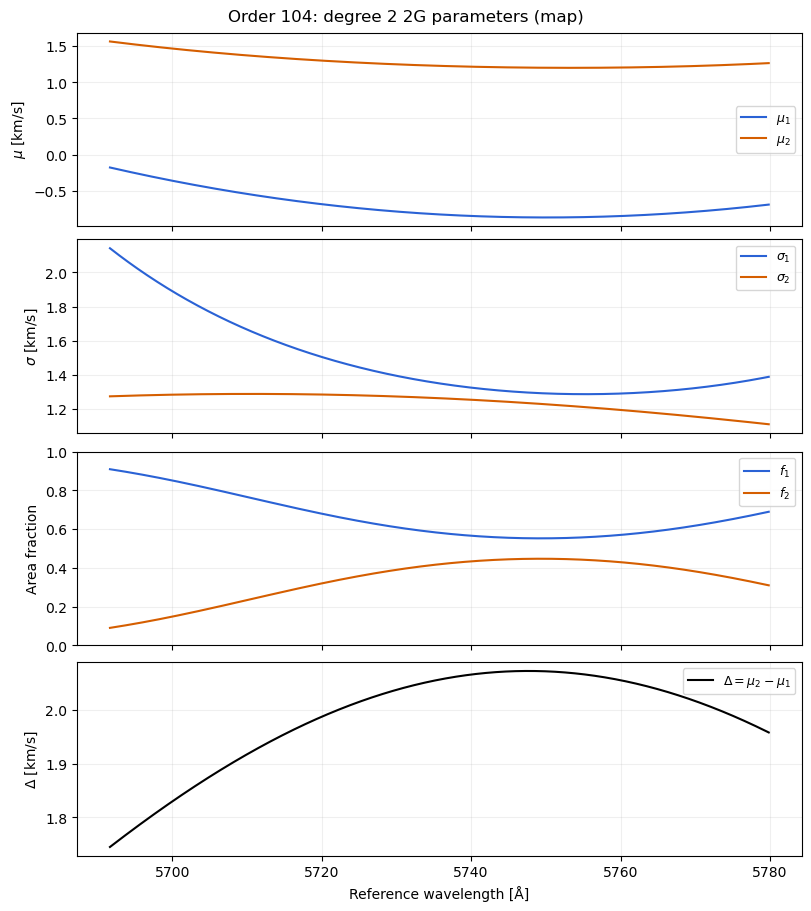

In [5]:
fig_parameters, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 9), layout='constrained')
colors = ['#2a62d5', '#d55e00']
for component, color in zip((1, 2), colors):
    axes[0].plot(wavelength, parameters[f'mu{component}_kms'], color=color,
                 label=rf'$\mu_{component}$')
    axes[1].plot(wavelength, parameters[f'sigma{component}_kms'], color=color,
                 label=rf'$\sigma_{component}$')
    axes[2].plot(wavelength, parameters[f'fraction{component}'], color=color,
                 label=rf'$f_{component}$')
axes[3].plot(wavelength, parameters['delta_kms'], color='k', label=r'$\Delta=\mu_2-\mu_1$')
for ax, label in zip(axes, [r'$\mu$ [km/s]', r'$\sigma$ [km/s]', 'Area fraction', r'$\Delta$ [km/s]']):
    ax.set_ylabel(label)
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
axes[2].set_ylim(0, 1)
axes[-1].set_xlabel('Reference wavelength [Å]')
fig_parameters.suptitle(f'Order {order}: degree {spec["degree"]} 2G parameters '
                       f'({spec["coefficient_estimate"]})')
display(fig_parameters)
plt.close(fig_parameters)


## Convert the mixture to cumulants

Compute the cumulants of the **whole normalized 2G profile**, not of its components separately. For centroid μ and central moments mₙ:

\[
\kappa_1=\mu,\quad \kappa_2=m_2,\quad \kappa_3=m_3,\quad
\kappa_4=m_4-3m_2^2,\quad \kappa_5=m_5-10m_2m_3.
\]

κₙ has units (km/s)ⁿ. These are unstandardized cumulants: κ₄ is not excess kurtosis (the latter is κ₄/κ₂²). The moments are analytic over the full intrinsic profile, with no finite velocity window or pixel integration. For a single Gaussian, κ₃–κ₅ are zero.


In [6]:
def mixture_cumulants(parameters):
    """Return columns kappa1,...,kappa5, in (km/s)**n."""
    weights = np.column_stack((parameters['fraction1'], parameters['fraction2']))
    means = np.column_stack((parameters['mu1_kms'], parameters['mu2_kms']))
    variances = np.column_stack((parameters['sigma1_kms']**2, parameters['sigma2_kms']**2))
    centroid = np.sum(weights*means, axis=1)
    offsets = means-centroid[:, None]
    m2 = np.sum(weights*(offsets**2+variances), axis=1)
    m3 = np.sum(weights*(offsets**3+3*offsets*variances), axis=1)
    m4 = np.sum(weights*(offsets**4+6*offsets**2*variances+3*variances**2), axis=1)
    m5 = np.sum(weights*(offsets**5+10*offsets**3*variances+15*offsets*variances**2), axis=1)
    return np.column_stack((centroid, m2, m3, m4-3*m2**2, m5-10*m2*m3))


kappa = mixture_cumulants(parameters)


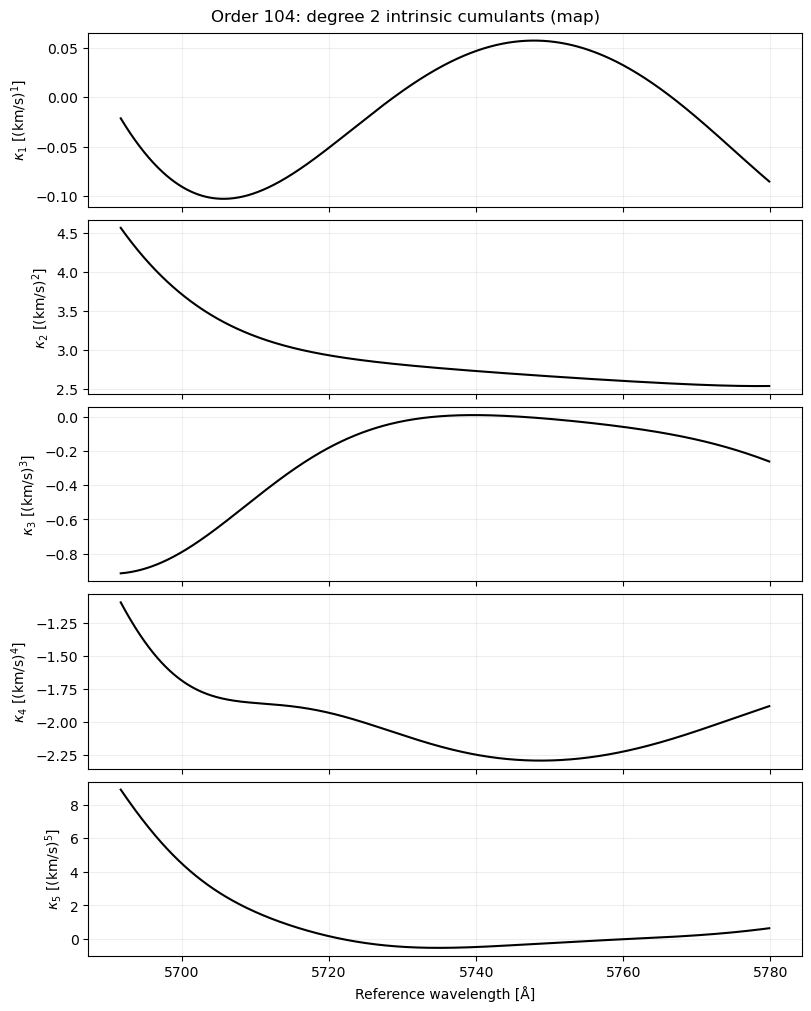

In [7]:
fig_cumulants, axes = plt.subplots(5, 1, sharex=True, figsize=(8, 10), layout='constrained')
for n, ax in enumerate(axes, start=1):
    ax.plot(wavelength, kappa[:, n-1], color='k', lw=1.5)
    ax.set_ylabel(rf'$\kappa_{n}$ [(km/s)$^{n}$]')
    ax.grid(alpha=.2)
axes[-1].set_xlabel('Reference wavelength [Å]')
fig_cumulants.suptitle(f'Order {order}: degree {spec["degree"]} intrinsic cumulants '
                      f'({spec["coefficient_estimate"]})')
display(fig_cumulants)
plt.close(fig_cumulants)


`parameters` contains the evaluated physical parameters, and `kappa[:, n-1]` contains κₙ. The following `shape` array follows the exact parameter order recorded in the JSON, so it can be passed to another implementation of the same 2G profile. Changing `n_wavelengths` only changes the plotting/evaluation grid.


In [8]:
shape_parameter_order = model['shape_parameter_order']
shape = np.column_stack([parameters[name] for name in shape_parameter_order])
print('shape columns:', shape_parameter_order)
print('shape:', shape.shape, 'kappa:', kappa.shape)


shape columns: ['sigma1_kms', 'fraction2', 'sigma2_kms', 'delta_kms', 'mu1_kms']
shape: (1000, 5) kappa: (1000, 5)
